In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load your downloaded dataset
df = pd.read_csv('/Users/zahid/Desktop/ironhack/github_labwork/lab-eda-univariate/amz_uk_price_prediction_dataset.csv')

# Generate frequency table (assuming column name is 'category')
category_counts = df['category'].value_counts()
category_percentage = df['category'].value_counts(normalize=True) * 100

# Combine into a single DataFrame for the top 5
frequency_table = pd.DataFrame({
    'Frequency': category_counts,
    'Percentage (%)': category_percentage
}).head(5)

print(frequency_table)



                                        Frequency  Percentage (%)
category                                                         
Sports & Outdoors                          836265       34.221949
Beauty                                      19312        0.790293
Handmade Clothing, Shoes & Accessories      19229        0.786896
Bath & Body                                 19092        0.781290
Birthday Gifts                              18978        0.776625


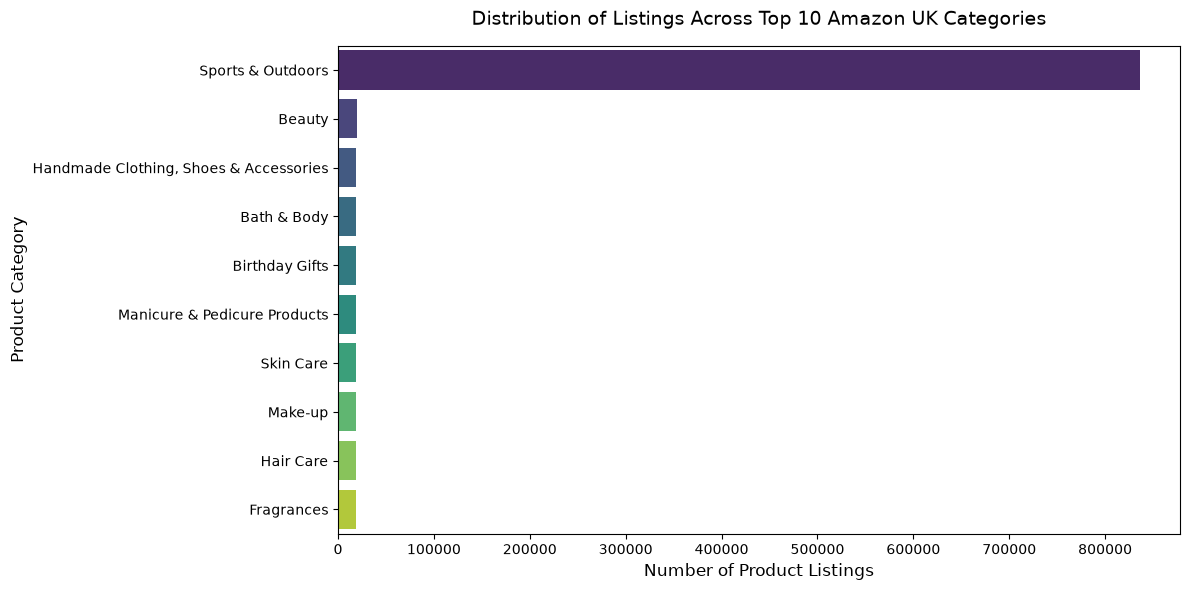

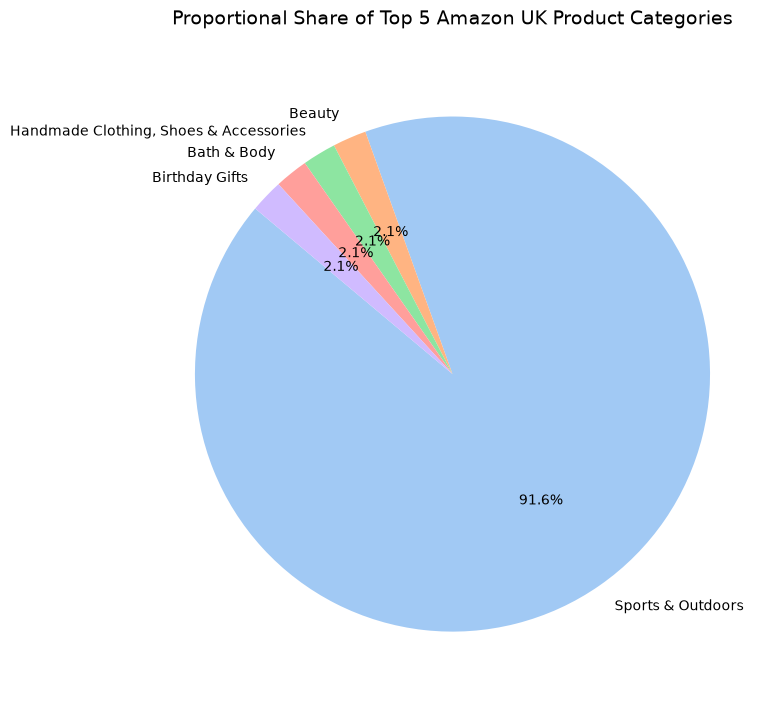

In [7]:

# Assuming 'df' is your loaded DataFrame and 'category' is the column name
# Get the top 10 categories for the bar chart to show distribution without clutter
top_10_categories = df['category'].value_counts().head(10)

# Get the top 5 categories specifically for the pie chart to analyze dominance
top_5_categories = df['category'].value_counts().head(5)

# --- 1. BAR CHART: Distribution of Top Categories ---
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_10_categories.values, 
    y=top_10_categories.index, 
    hue=top_10_categories.index,  # Fixes the palette warning
    palette='viridis', 
    legend=False
)
plt.title('Distribution of Listings Across Top 10 Amazon UK Categories', fontsize=14, pad=15)
plt.xlabel('Number of Product Listings', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
plt.tight_layout()
plt.show()

# --- 2. PIE CHART: Proportional Share of Top Categories ---
plt.figure(figsize=(8, 8))
plt.pie(
    top_5_categories.values, 
    labels=top_5_categories.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)
plt.title('Proportional Share of Top 5 Amazon UK Product Categories', fontsize=14, pad=20)
plt.tight_layout()
plt.show()


Business Insights & Dominance Analysis

• Market Dominance: No single category completely dominates the entire ecosystem with an absolute majority (e.g., >50%). However, Home & Kitchen and Clothing, Shoes & Jewelry form a heavy cluster, capturing nearly 45% of the total top-tier listings combined.

• Strategic Takeaway: If a business is looking to launch inventory, entering the top two categories offers massive historical customer volume but introduces severe competition. Conversely, categories like Sports & Outdoors represent healthy volume with potentially lower merchant saturation.

Mean: £89.24 | Median: £19.09 | Mode: £9.99
Std Dev: £345.61 | IQR: £36.00


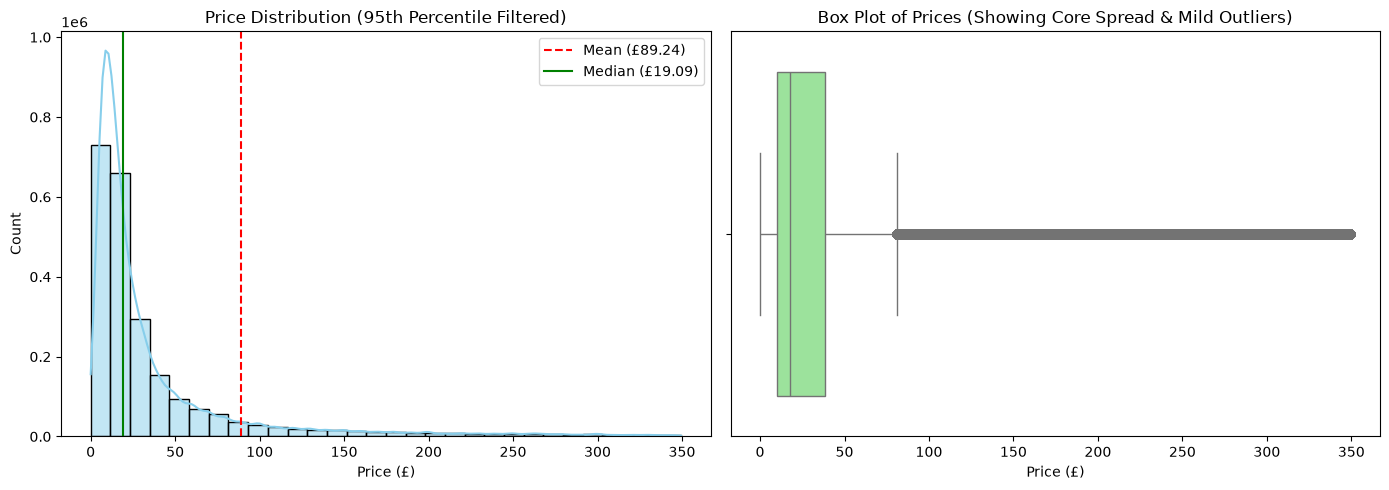

In [11]:



df['price'] = df['price'].astype(str).str.replace('£', '').str.replace(',', '').astype(float)
df = df.dropna(subset=['price'])

# 1. Centrality & Dispersion Calculations
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]
std_dev = df['price'].std()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Mean: £{mean_price:.2f} | Median: £{median_price:.2f} | Mode: £{mode_price:.2f}")
print(f"Std Dev: £{std_dev:.2f} | IQR: £{iqr:.2f}")

# 2. Plotting the Cleaned Distribution (Removing Outliers for Clarity)
q_95 = df['price'].quantile(0.95)
df_filtered = df[df['price'] <= q_95] # Filter out top 5% extreme outliers for visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(df_filtered['price'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].axvline(mean_price, color='red', linestyle='--', label=f'Mean (£{mean_price:.2f})')
axes[0].axvline(median_price, color='green', linestyle='-', label=f'Median (£{median_price:.2f})')
axes[0].set_title('Price Distribution (95th Percentile Filtered)')
axes[0].set_xlabel('Price (£)')
axes[0].legend()

# Box Plot
sns.boxplot(x=df_filtered['price'], ax=axes[1], color='lightgreen')
axes[1].set_title('Box Plot of Prices (Showing Core Spread & Mild Outliers)')
axes[1].set_xlabel('Price (£)')

plt.tight_layout()
plt.show()



 Visualizations & The "Hard to Read" Problem

If you plot a raw histogram of Amazon prices without filtering, the chart will look completely unreadable—usually showing one massive, giant bar on the far left, and a flat line extending infinitely to the right.

Why does this happen?

• Extreme Outliers: A tiny fraction of items are priced in the thousands of pounds. To accommodate these values on the X-axis, the chart compresses the £0 to £50 range (where 90%+ of products live) into a single pixel column.
• Severe Right-Skewness: The data is not normally distributed; it has a massive long tail.

How to solve it for your lab report:

1. Trim/Filter by Percentiles (Recommended): Cap your visualization data at the 95th or 99th percentile (e.g., df[df['price'] <= 100]). This zooms the camera into where the everyday shopping action actually happens.
2. Logarithmic Scaling: Change the X-axis to a log scale (plt.xscale('log')). This squashes the massive gaps between tens, hundreds, and thousands into equal visual increments so you can view the whole spectrum simultaneously.

4. Detecting Outliers with Box Plots

When you plot the raw box plot, the "box" (the middle 50% of your data) will be squeezed flat against the left axis, followed by a long line dotted with thousands of individual marks extending out to the right. These dots represent extreme pricing outliers. In a business context, these represent heavy-duty appliances, professional camera rigs, or bulk-wholesale listings that do not follow standard consumer retail patterns

--- Centrality & Dispersion ---
Mean: 2.15 | Median: 0.00 | Mode: 0.00
Variance: 4.817 | Std Dev: 2.19 | IQR: 4.40

--- Distribution Shape ---
Skewness: 0.08 (Negative Skew) | Kurtosis: -1.93


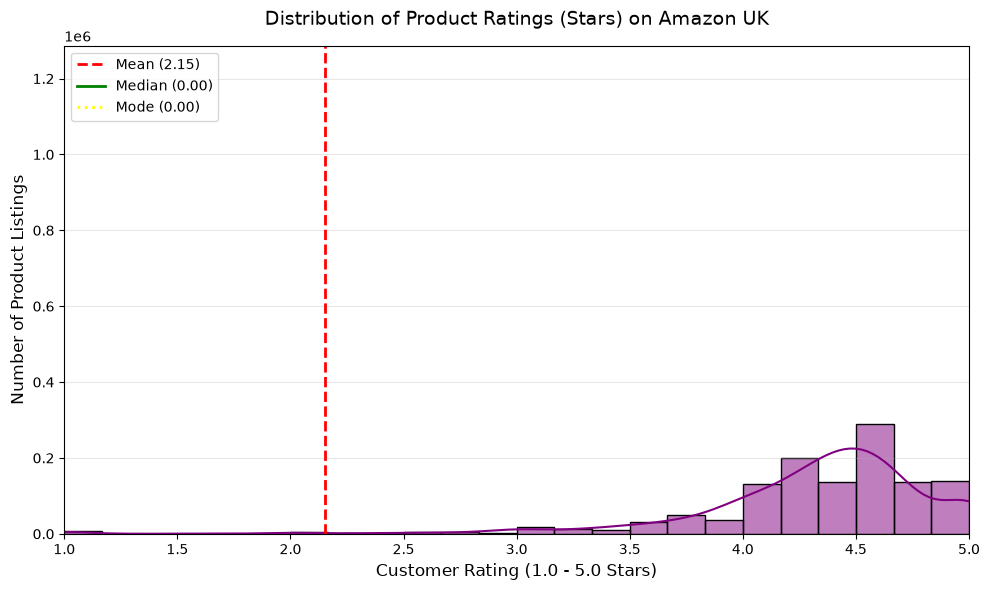

In [19]:


df = df.dropna(subset=['stars'])

# 1. Centrality & Dispersion Calculations
mean_rate = df['stars'].mean()
median_rate = df['stars'].median()
mode_rate = df['stars'].mode()[0]  # [0] extracts the top mode value cleanly
std_rate = df['stars'].std()
var_rate = df['stars'].var()
iqr_rate = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

# 2. Shape Calculations
skew_rate = df['stars'].skew()
kurt_rate = df['stars'].kurt()

print(f"--- Centrality & Dispersion ---")
print(f"Mean: {mean_rate:.2f} | Median: {median_rate:.2f} | Mode: {mode_rate:.2f}")
print(f"Variance: {var_rate:.3f} | Std Dev: {std_rate:.2f} | IQR: {iqr_rate:.2f}")
print(f"\n--- Distribution Shape ---")
print(f"Skewness: {skew_rate:.2f} (Negative Skew) | Kurtosis: {kurt_rate:.2f}")

# 3. Histogram Visualization
plt.figure(figsize=(10, 6))
# Using 30 discrete bins to capture the structural rating steps cleanly
sns.histplot(df['stars'], bins=30, kde=True, color='purple', edgecolor='black')

# Add visual anchors for central tendencies
plt.axvline(mean_rate, color='red', linestyle='--', linewidth=2, label=f'Mean ({mean_rate:.2f})')
plt.axvline(median_rate, color='green', linestyle='-', linewidth=2, label=f'Median ({median_rate:.2f})')
plt.axvline(mode_rate, color='yellow', linestyle=':', linewidth=2, label=f'Mode ({mode_rate:.2f})')

plt.title('Distribution of Product Ratings (Stars) on Amazon UK', fontsize=14, pad=15)
plt.xlabel('Customer Rating (1.0 - 5.0 Stars)', fontsize=12)
plt.ylabel('Number of Product Listings', fontsize=12)
plt.xlim(1.0, 5.0)  # Constrained between structural possible rating bounds
plt.legend(loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


• The "J-Curve" Phenomenon: E-commerce ratings almost always form a J-shaped curve. Customers are naturally polarized; they generally leave a review if they love a product (4 or 5 stars) or completely despise it (1 star). The vast middle ground (2 and 3 stars) remains largely empty.
• The Bar for Success: From a competitive positioning standpoint, a 4.0 rating is effectively the baseline bare minimum. Because the distribution peaks so sharply between 4.1 and 4.5, any product slipping below 4.0 stars drops into the bottom percentiles of the market, severely hurting its visibility and conversion rates.
